# 24. Origin time from the airwave and the weather

The explosion origin time is found from the airwave onsets at the working infraBSUs and the airwave
speed predicted from the weather at the time:

* **weather**: surface observations within ±30 min of the origin at XMR (Cape Canaveral Skid Strip, 2 km
  from LC-36) and TTS (Shuttle Landing Facility, inside the network), from the Iowa Environmental
  Mesonet ASOS archive (`data/`). No radiosonde was archived for 00 UTC;
* **speed**: still-air speed from temperature, humidity and pressure (Cramer 1993,
  `ksclib.physics.event_airwave_speeds`), plus the mean wind vector projected on each source-to-station
  ray;
* **origin**: $t_0 = t_{onset,i} - d_i / c_{eff,i}$ averaged over stations, for several onset definitions,
  compared with a straight-line fit $t = t_0 + d/c$ with $c$ free.

Output (`cfg.OUT_DIR / "24_origin_time"`): `weather_at_origin.csv`, `airwave_speeds.csv`,
`origin_time_picks.csv`, `origin_time_fit.csv`, `origin_time.png`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ksclib import weather
import newglenn_config as cfg

warnings.filterwarnings('ignore', message='ObsPy can not map unit')
OUT = cfg.output_dir('24_origin_time')
O_CFG = cfg.ORIGIN                      # origin_time in newglenn.yaml
stations = cfg.station_table()
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
print('origin in newglenn.yaml:', O_CFG)

origin in newglenn.yaml: 2026-05-29T01:00:02.370000Z


## Weather at the origin

In [2]:
obs, per, mean = cfg.weather_at_origin()
display(obs[['station', 'datetime_utc', 'temperature_c', 'relative_humidity_percent',
             'wind_direction_from_deg', 'wind_speed_knots']].round(2))
spd, frm = weather.wind_from_uv(mean['u'], mean['v'])
per['wind_speed_mps'], per['wind_from_deg'] = weather.wind_from_uv(per['u'].to_numpy(), per['v'].to_numpy())
display(per.round(2))
print(f"Used (mean of {cfg.EVENT.raw['weather']['stations']}): {mean['temperature_c']:.2f} C, {mean['rh']:.1f}% RH, "
      f"{mean['pressure_pa'] / 100:.1f} hPa, wind {float(spd):.2f} m/s from {float(frm):.0f} deg")
per.to_csv(OUT / 'weather_at_origin.csv')

/var/folders/yj/6sjdgxm52t5d_p4w0lcrsrzr0000gp/T/ipykernel_56521/2106950754.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  'wind_direction_from_deg', 'wind_speed_knots']].round(2))


,station,datetime_utc,temperature_c,relative_humidity_percent,wind_direction_from_deg,wind_speed_knots
9,TTS,2026-05-29 00:45:00+00:00,26.00,83.59,300.0,4.0
10,XMR,2026-05-29 00:53:00+00:00,27.00,88.86,290.0,6.0
11,XMR,2026-05-29 00:55:00+00:00,27.22,84.01,300.0,9.0
12,COF,2026-05-29 00:55:00+00:00,28.33,80.86,290.0,10.0
13,TTS,2026-05-29 00:55:00+00:00,25.56,89.04,300.0,3.0
14,TTS,2026-05-29 01:00:00+00:00,26.00,88.78,0.0,0.0
15,TTS,2026-05-29 01:03:00+00:00,26.00,88.78,0.0,0.0
16,TTS,2026-05-29 01:04:00+00:00,26.00,88.78,0.0,0.0
17,TTS,2026-05-29 01:06:00+00:00,26.00,88.78,0.0,0.0
18,TTS,2026-05-29 01:07:00+00:00,26.00,88.78,0.0,0.0


,temperature_c,rh,u,v,pressure_pa,n,wind_speed_mps,wind_from_deg
station,,,,,,,,
COF,28.33,80.86,4.83,-1.76,101400.0,1,5.14,290.0
TTS,25.82,88.84,0.39,-0.23,101430.0,8,0.45,300.0
XMR,27.07,85.52,3.49,-1.81,101360.0,3,3.93,297.4


Used (mean of ['XMR', 'TTS']): 26.45 C, 87.2% RH, 1014.0 hPa, wind 2.19 m/s from 298 deg


## Predicted airwave speed to each station

The rays run north-north-west (azimuths 321–346°); the light west-north-westerly wind is a 1.5–2 m/s
headwind on all of them. Rows for stations without working infraBSUs are kept for completeness.

In [3]:
sp = cfg.airwave_speeds(mean)
sp_xmr = cfg.airwave_speeds(per.loc['XMR'])
sp_calm = cfg.airwave_speeds(mean, wind=False)
sp.to_csv(OUT / 'airwave_speeds.csv')
display(sp.sort_values('distance_m').round(2))

,distance_m,azimuth_deg,c0_mps,wind_along_ray_mps,c_eff_mps,travel_time_s
station,,,,,,
B20S,11764.48,345.54,348.74,-1.47,347.27,33.88
B20,11793.38,345.58,348.74,-1.47,347.27,33.96
B20W,11814.01,345.47,348.74,-1.47,347.26,34.02
B23,13587.30,331.82,348.74,-1.81,346.92,39.17
B24,15550.76,321.65,348.74,-2.00,346.73,44.85
B24LT,15672.36,321.05,348.74,-2.01,346.72,45.20
B24RE,15751.39,321.12,348.74,-2.01,346.73,45.43
B07,15977.54,341.45,348.74,-1.58,347.15,46.02
B01,17867.41,339.34,348.74,-1.64,347.10,51.48


## Onsets

Onset = first sample above a fraction of the channel's peak (>0.5 Hz), for fractions 5%, 10% and 20%, but
never below 5 times the pre-event noise (B14 CD0 and B05 CD0 are noisy). The 5% and 10% onsets are searched
in the 3 s before the 20% onset. The smaller fractions are closer to the true first break; the 20% pick is
later where the pulse is less steep.

In [4]:
raw = cfg.event_stream_raw(starttime=O_CFG - 300, endtime=O_CFG + 300)
st = cfg.instrument_correct(raw)
CH = ['1R.B20.00.HD1', '1R.B14.00.CD0', '1R.B14.00.CD1', '1R.B14.00.CD2', '1R.B29.00.CD0', '1R.B05.00.CD0']
FRACS = (0.05, 0.10, 0.20)
rows = []
for sid in CH:
    tr = st.select(id=sid)[0].copy().filter('highpass', freq=0.5, corners=4, zerophase=True)
    sta = tr.stats.station
    t_air = sp.travel_time_s[sta]
    s = tr.slice(O_CFG - 60, O_CFG + 120)
    a, fs = np.abs(s.data), s.stats.sampling_rate
    noise = np.sqrt(np.mean(tr.slice(O_CFG - 250, O_CFG - 60).data ** 2))
    r = dict(id=sid, station=sta, distance_m=sp.distance_m[sta], peak_pa=a.max(), noise_pa=noise)
    i20 = np.argmax(a > 0.2 * a.max())                     # coarse pick; finer ones searched in the 3 s before
    i0 = max(0, i20 - int(3 * fs))
    for f in FRACS:
        thr = max(f * a.max(), 5 * noise)
        r[f'onset_{int(f * 100):02d}'] = float(s.stats.starttime + (i0 + np.argmax(a[i0:i20 + 1] > thr)) / fs)
        r[f'thr_{int(f * 100):02d}_pa'] = thr
    rows.append(r)
picks = pd.DataFrame(rows)
for f in FRACS:
    k = f'onset_{int(f * 100):02d}'
    picks[k] = picks[k] - float(O_CFG.timestamp)      # seconds after the configured origin
picks.to_csv(OUT / 'origin_time_picks.csv', index=False)
display(picks.round(3))

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:136: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


,id,station,distance_m,peak_pa,noise_pa,onset_05,thr_05_pa,onset_10,thr_10_pa,onset_20,thr_20_pa
0,1R.B20.00.HD1,B20,11793.383,364.401,0.060,33.620,18.220,33.790,36.440,34.260,72.880
1,1R.B14.00.CD0,B14,19311.802,235.947,4.615,55.614,23.076,55.614,23.595,56.146,47.189
2,1R.B14.00.CD1,B14,19311.802,304.820,1.250,55.524,15.241,55.688,30.482,56.144,60.964
3,1R.B14.00.CD2,B14,19311.802,244.015,0.048,55.524,12.201,55.692,24.402,56.146,48.803
4,1R.B29.00.CD0,B29,21002.680,296.351,0.029,60.996,14.818,61.504,29.635,61.508,59.270
5,1R.B05.00.CD0,B05,21303.715,255.530,4.730,61.578,23.648,61.634,25.553,62.072,51.106


## Origin time

In [5]:
fits = []
for f in FRACS:
    k = f'onset_{int(f * 100):02d}'
    t, d = picks[k].to_numpy(), picks.distance_m.to_numpy()
    for lab, s_ in (('weather + wind', sp), ('XMR only + wind', sp_xmr), ('weather, no wind', sp_calm)):
        t0i = t - picks.station.map(s_.travel_time_s).to_numpy()
        fits.append(dict(onset=k, model=lab, t0_s=t0i.mean(), spread_s=t0i.std(ddof=1),
                         c_mps=np.mean(picks.station.map(s_.c_eff_mps)),
                         trend_s_per_km=np.polyfit(d / 1000, t0i, 1)[0]))
    slope, icpt = np.polyfit(d, t, 1)
    fits.append(dict(onset=k, model='free c', t0_s=icpt, spread_s=np.std(t - (icpt + slope * d), ddof=2),
                     c_mps=1 / slope, trend_s_per_km=0.0))
fits = pd.DataFrame(fits)
fits['origin_time'] = [str(O_CFG + x)[:23] for x in fits.t0_s]
fits.to_csv(OUT / 'origin_time_fit.csv', index=False)
display(fits.round(3))

,onset,model,t0_s,spread_s,c_mps,trend_s_per_km,origin_time
0,onset_05,weather + wind,-0.002,0.265,347.020,0.059,2026-05-29T01:00:02.367
1,onset_05,XMR only + wind,-0.154,0.223,346.062,0.047,2026-05-29T01:00:02.215
2,onset_05,"weather, no wind",0.266,0.331,348.736,0.079,2026-05-29T01:00:02.635
3,onset_05,free c,-1.201,0.208,339.438,0.000,2026-05-29T01:00:01.169
4,onset_10,weather + wind,0.175,0.391,347.020,0.065,2026-05-29T01:00:02.545
5,onset_10,XMR only + wind,0.023,0.354,346.062,0.053,2026-05-29T01:00:02.393
6,onset_10,"weather, no wind",0.444,0.449,348.736,0.085,2026-05-29T01:00:02.813
7,onset_10,free c,-1.138,0.377,338.733,0.000,2026-05-29T01:00:01.232
8,onset_20,weather + wind,0.568,0.214,347.020,0.046,2026-05-29T01:00:02.937
9,onset_20,XMR only + wind,0.416,0.171,346.062,0.034,2026-05-29T01:00:02.785


Preferred origin: 2026-05-29T01:00:02.367624Z (5% onsets, weather + wind; station spread 0.27 s)
Free-speed fit, same onsets: 2026-05-29T01:00:01.169255Z at 339.4 m/s
Shift from newglenn.yaml origin: -0.00 s


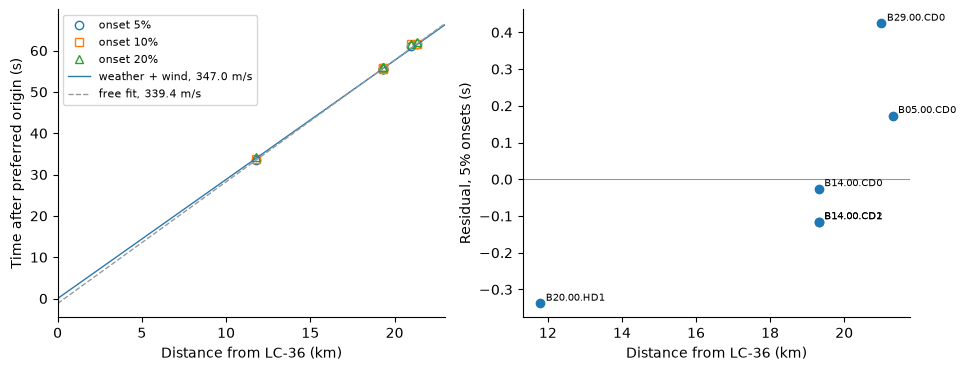

In [6]:
best = fits[(fits.onset == 'onset_05') & (fits.model == 'weather + wind')].iloc[0]
ORIGIN = O_CFG + best.t0_s
free = fits[(fits.onset == 'onset_05') & (fits.model == 'free c')].iloc[0]
print(f'Preferred origin: {ORIGIN} (5% onsets, weather + wind; station spread {best.spread_s:.2f} s)')
print(f'Free-speed fit, same onsets: {O_CFG + free.t0_s} at {free.c_mps:.1f} m/s')
print(f'Shift from newglenn.yaml origin: {best.t0_s:+.2f} s')

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
d = picks.distance_m / 1000
for f, mk in zip(FRACS, 'os^'):
    k = f'onset_{int(f * 100):02d}'
    axs[0].plot(d, picks[k] - best.t0_s, mk, mfc='none', label=f'onset {int(f * 100)}%')
dd = np.linspace(0, 23, 50)
c = best.c_mps
axs[0].plot(dd, dd * 1000 / c, '-', color='#2a7ab0', lw=1, label=f'weather + wind, {c:.1f} m/s')
axs[0].plot(dd, (free.t0_s - best.t0_s) + dd * 1000 / free.c_mps, '--', color='#999999', lw=1,
            label=f'free fit, {free.c_mps:.1f} m/s')
axs[0].set(xlabel='Distance from LC-36 (km)', ylabel='Time after preferred origin (s)', xlim=(0, 23))
axs[0].legend(fontsize=8)
k = 'onset_05'
res = picks[k] - best.t0_s - picks.station.map(sp.travel_time_s)
axs[1].plot(d, res, 'o')
for _, r in picks.iterrows():
    axs[1].annotate(r.id.split('.', 1)[1], (r.distance_m / 1000, res[_]), xytext=(4, 2), textcoords='offset points', fontsize=7)
axs[1].axhline(0, color='#999999', lw=0.8)
axs[1].set(xlabel='Distance from LC-36 (km)', ylabel='Residual, 5% onsets (s)')
fig.savefig(OUT / 'origin_time.png', dpi=150, bbox_inches='tight')

## Result

* **Weather.** At XMR and TTS around 01:00 UTC: 26.4 °C, 87% RH, 1014 hPa, and a light west-north-westerly
  wind (2.2 m/s from 298° on average; 3.9 m/s at XMR, nearly calm at TTS).
* **Speed.** Still-air 348.7 m/s (Cramer 1993). The wind is a 1.5–2.0 m/s headwind on every ray, giving
  346.7–347.3 m/s.
* **Origin.** 5% onsets with the weather-based speeds give **01:00:02.37 UTC**, with a station spread of
  0.27 s. Other onset definitions and weather choices give 01:00:02.2–03.2. This is the value now in
  `newglenn.yaml`.
* **Check.** A free-speed fit to the same onsets gives 01:00:01.2 at 339 m/s. The per-station origins drift
  about +0.06 s/km with distance: the airwave arrives slightly later at the far stations than the surface
  weather predicts, by about 2% in speed. That could come from a cooler layer near the ground (TTS, inside
  the network, was 1.3 °C cooler than XMR at the pad), from the wind profile above 10 m, or from the pulse
  broadening with distance. The origin uncertainty is therefore about ±1 s.